# Qwen2.5-0.5B gọi công cụ: cách A (cách của Claude)

**Mục tiêu.** Dạy model nhỏ Qwen2.5-0.5B-Instruct nhận một câu nói của operator cùng trạng thái máy, rồi chọn **đúng 1 trong 11 công cụ**
(kèm tham số đúng) hoặc **không chọn công cụ nào** nếu câu nói không liên quan đến băng tải. Model phải trả lời trong khoảng 2 giây
và nằm gọn trong ngân sách RAM của Arduino UNO Q (4 GB, dùng chung với các phần khác của hệ thống).

**Notebook này làm gì, theo thứ tự**

| # | Bước | Vì sao làm vậy |
|---|---|---|
| 1 | Sinh dữ liệu bằng chương trình (1950 mẫu) | Nhãn luôn đúng. Có cặp câu gần giống nhưng khác tool, câu ngoài phạm vi chứa từ khoá "bẫy", số viết bằng chữ và lỗi chính tả giống nhận dạng giọng nói |
| 2 | Đo model gốc (chưa dạy) | Có mốc để biết việc dạy thêm được bao nhiêu |
| 3 | Dạy bằng **LoRA** | Model 0.5B dạy toàn bộ trọng số sẽ tràn GPU 12 GB. LoRA chỉ học thêm vài ma trận nhỏ |
| 4 | Đổi sang GGUF và nén thành nhiều mức | UNO Q chạy llama.cpp nên cần GGUF. Nén làm model nhỏ và nhanh hơn |
| 5 | Đo từng mức nén trên CPU | Chọn bằng số liệu: mức nhỏ nhất mà điểm không giảm quá 2 điểm |
| 6 | Phân tích lỗi và đo trên câu thật (nếu có) | Biết model còn sai ở đâu |

**Hai kỹ thuật dùng suốt notebook (không phải model học mà là cách ghép hệ thống):**
- *Prompt đặt phần cố định lên đầu*: mô tả 11 công cụ nằm ở đầu, trạng thái máy và câu nói nằm cuối. llama.cpp nhớ phần đầu đã đọc,
  nên mỗi câu hỏi chỉ phải đọc phần cuối.
- *Ép đầu ra bằng JSON schema*: model chỉ được viết ra tên công cụ có thật và giá trị tham số hợp lệ. Nhãn `action_type`
  được suy ra bằng code từ `tool_call` vì model nhỏ hay ghi sai nhãn này.

**Cần có trong thư mục làm việc:** `tool_cases.py`, `slm_tools.py`, `model_catalog.py`, `make_train.py`, `train_sft.py`, `lora_train.py`,
`gguf_tools.py`, `eval_tools.py`, thư mục `llama.cpp` (có `convert_hf_to_gguf.py` và các chương trình `llama-quantize`, `llama-imatrix`).

**Thời gian ước tính** (GPU 12 GB, đo trên CPU): dạy khoảng 15-25 phút, nén vài phút, đo 5 mức nén khoảng 30-40 phút.

## 1. Chuẩn bị

Cài thêm thư viện `peft` (LoRA) nếu chưa có, rồi nạp các module của dự án.

In [1]:
%pip install -q peft pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys
from pathlib import Path
if Path.cwd().name == 'finetuning':
    os.chdir('..')
for _p in (Path.cwd(), Path.cwd() / 'finetuning'):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch

import eval_tools as E          # đo độ chính xác, RAM, tốc độ
import gguf_tools               # đổi sang GGUF và nén
import lora_train               # dạy bằng LoRA
import make_train               # sinh dữ liệu
import model_catalog as catalog
import tool_cases as T          # 11 công cụ và bộ test 156 câu

### Cấu hình của lần chạy này

Mọi lựa chọn nằm trong một ô để dễ đổi. Các tham số LoRA:
- `r` và `alpha`: kích thước phần học thêm. `r` lớn thì học được nhiều hơn nhưng tốn hơn. `alpha / r = 2` là mức thường dùng.
- `lr`: tốc độ học. LoRA chịu được tốc độ học cao hơn dạy toàn bộ model.
- `bs x accum`: mỗi bước cập nhật dùng `bs * accum = 16` mẫu. Để `bs=1` cho khỏi hết bộ nhớ GPU (từ vựng của Qwen rất lớn).
- `epochs`: số lần đi qua toàn bộ dữ liệu.

In [3]:
BASE_NAME = "Qwen2.5-0.5B-Instruct"          # tên trong model_catalog
HF_REPO = "Qwen/Qwen2.5-0.5B-Instruct"       # nơi tải trọng số gốc
LLAMA_DIR = "./llama.cpp"                    # thư mục llama.cpp

RUN_DIR = Path("runs/qwen05_A")              # mọi file của lần chạy này nằm ở đây
TRAIN_FILE = RUN_DIR / "train_v2.jsonl"
HELD_FILE = RUN_DIR / "heldout_v2.json"
MERGED_DIR = RUN_DIR / "merged"              # model đã gộp LoRA (định dạng Hugging Face)
GGUF_DIR = RUN_DIR / "gguf"

LORA = dict(r=64, alpha=128, dropout=0.05, lr=2e-4, epochs=3, bs=1, accum=16)
QUANTS = ["Q8_0", "Q5_K_M", "Q4_K_M", "Q4_K_M-imat"]   # các mức nén sẽ thử (ngoài F16)
RETRAIN = False                              # True để dạy lại dù đã có kết quả

RUN_DIR.mkdir(parents=True, exist_ok=True)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "không có (sẽ rất chậm)")

GPU: NVIDIA GeForce RTX 4070


## 2. Bài toán: model nhìn thấy gì

Mỗi lần hỏi, model nhận **một prompt gồm hai phần**:
1. Phần cố định: hướng dẫn và mô tả 11 công cụ (luôn giống nhau).
2. Phần thay đổi: trạng thái máy (`fsm_state`, telemetry) và câu nói của operator.

Nó phải trả về một JSON: gọi công cụ nào với tham số gì, hoặc `null` nếu không có công cụ phù hợp.

In [4]:
test_cases = E.test156()
print(f"Bộ test gốc của dự án: {len(test_cases)} câu")
print("11 công cụ:", ", ".join(T.NAMES))

example = test_cases[0]
messages = make_train.messages_cached(example, T.NAMES)
print("\n--- Phần thay đổi (model đọc lại mỗi lần) ---")
print(messages[1]["content"])
print(f"\nPhần cố định (hướng dẫn + mô tả 11 công cụ): {len(messages[0]['content'])} ký tự, được cache")
print("\n--- Đáp án đúng cho câu này ---")
print(json.dumps(make_train.target_json(example), indent=1))

Bộ test gốc của dự án: 156 câu
11 công cụ: query_blackbox_logs, request_line_restart, trigger_audio_alarm, get_live_telemetry, get_last_stop_reason, request_line_stop, get_production_stats, get_inspection_summary, request_set_speed, acknowledge_alarm, set_led_indicator

--- Phần thay đổi (model đọc lại mỗi lần) ---
{"fsm_state":"JAMMED","telemetry":{"belt_speed_rpm":0,"motor_current_ma":2900,"motor_temp_c":48.0},"user_prompt":"Look at the history of current draw."}

Phần cố định (hướng dẫn + mô tả 11 công cụ): 3592 ký tự, được cache

--- Đáp án đúng cho câu này ---
{
 "action_type": "TOOL_REQUEST",
 "tool_call": {
  "tool_name": "query_blackbox_logs",
  "arguments": {
   "target_metric": "current"
  }
 },
 "response_text": ""
}


## 3. Dữ liệu huấn luyện

Dữ liệu được **sinh bằng chương trình** (`make_train.py`) nên nhãn luôn chính xác: chương trình chọn trước công cụ và tham số đúng,
rồi mới viết thành câu nói. Có ba bộ câu tách biệt:

| Bộ | Dùng để | Câu từ đâu |
|---|---|---|
| train | dạy model | các mẫu câu "train" do mình viết |
| held | kiểm tra model có hiểu hay chỉ nhớ | các mẫu câu **chưa từng xuất hiện** trong train |
| test 156 | bộ gốc của dự án, so sánh giữa mọi model | `tool_cases.py` |

**Những điều làm dữ liệu khó hơn, để model không học đường tắt theo từ khoá:**
- câu gần giống nhưng khác công cụ: "stop the belt" (dừng) và "why did the belt stop" (hỏi lý do dừng);
- câu ngoài phạm vi chứa từ khoá của công cụ: "set a timer for ten minutes", "my car inspection is due next week";
- số viết bằng chữ ("forty five rpm") và lỗi chính tả như nhận dạng giọng nói ("imediately", "r p m");
- trạng thái máy thường hợp lý với lệnh nhưng 30% ngẫu nhiên, để model đọc câu nói thay vì đoán theo trạng thái.

Hàm `build_dataset()` còn **tự dừng nếu một câu train trùng với held hoặc test**, và kiểm tra mọi nhãn bằng chính scorer của dự án.

In [5]:
train, held = make_train.build_dataset()

with open(TRAIN_FILE, "w", encoding="utf-8") as f:
    for row in make_train.to_chat_rows(train):
        f.write(json.dumps(row, ensure_ascii=False) + "\n")
json.dump(held, open(HELD_FILE, "w", encoding="utf-8"), ensure_ascii=False)

name_of = lambda case: case["tool"] or "(ngoài phạm vi)"
pd.DataFrame({"train": Counter(map(name_of, train)), "held": Counter(map(name_of, held))})

,train,held
get_live_telemetry,150,12
(ngoài phạm vi),300,24
trigger_audio_alarm,150,12
get_production_stats,150,12
get_inspection_summary,150,12
acknowledge_alarm,150,12
request_line_stop,150,12
query_blackbox_logs,150,12
get_last_stop_reason,150,12
request_line_restart,150,12


Một vài mẫu để xem bằng mắt (câu nói và công cụ đúng):

In [6]:
import random
random.seed(3)
pd.DataFrame([{"câu nói": c["context"]["user_prompt"], "công cụ đúng": name_of(c), "tham số": c["args"]}
              for c in random.sample(train, 10)])

,câu nói,công cụ đúng,tham số
0,Throughput numbers for today.,get_production_stats,{'period': 'today'}
1,Get the belt going again at thirty rpm.,request_line_restart,{'target_speed_rpm': 30}
2,okay what is our production total during my shift,get_production_stats,{'period': 'this_shift'}
3,uh stop the conveyor immediately plese,request_line_stop,{}
4,i want items produced history for the previous...,query_blackbox_logs,"{'target_metric': 'product_count', 'lookback_m..."
5,What are we seeing for power draw right now.,get_live_telemetry,{'metric': 'current'}
6,show solid red status light,set_led_indicator,"{'color': 'red', 'pattern': 'solid'}"
7,problem solved you can silence the alert now,acknowledge_alarm,{}
8,um give me reason for the last stoppage,get_last_stop_reason,{}
9,bring the conveyor to a halt,request_line_stop,{}


## 4. Mốc gốc: model chưa được dạy

Đo model gốc (định dạng F16, chưa nén) trên hai bộ câu: 156 câu của dự án và bộ giữ riêng.
Chạy bằng **CPU** (`gpu_layers=0`) cho giống Arduino UNO Q, nên RAM và tốc độ có thể so sánh.

Các cột trong bảng kết quả:
- `ok_156`, `ok_lạ`: tỉ lệ câu đúng cả công cụ lẫn tham số trên hai bộ.
- `over_*`: tỉ lệ câu ngoài phạm vi mà model lại gọi công cụ (càng thấp càng tốt).
- `p50_*`, `p95_*`: thời gian trả lời (giây) của câu thường và của 5% câu chậm nhất.
- `ram_mb`: RAM đỉnh của tiến trình model.

In [7]:
catalog.ensure_gguf(BASE_NAME, "F16", llama_cpp_dir=LLAMA_DIR)       # tải và đổi sang GGUF nếu chưa có
base_cfg = E.find_cfg("Qwen2.5-0.5B", "F16")

EVAL_SETS = {"156": test_cases, "lạ": E.heldout(HELD_FILE)}
baseline = E.measure_point(base_cfg, "Qwen gốc (F16)", EVAL_SETS, gpu_layers=0)
pd.DataFrame([baseline])

,model,file_mb,ok_156,over_156,p50_156,p95_156,ok_lạ,over_lạ,p50_lạ,p95_lạ,ram_mb
0,Qwen gốc (F16),948.1,0.327,0.917,1.37,1.75,0.314,1.0,1.39,1.8,1075.5


## 5. Dạy bằng LoRA

**LoRA** đóng băng toàn bộ trọng số gốc và chỉ học thêm các ma trận nhỏ gắn vào các lớp tuyến tính. Chỉ khoảng 1-10% tham số được học
nên tốn rất ít bộ nhớ. Sau khi dạy xong, `train_lora` **gộp** phần học thêm vào trọng số gốc, nên kết quả là một model bình thường
và đổi sang GGUF được.

Chỉ **phần câu trả lời** của model bị chấm điểm lỗi (khoảng 50 token mỗi mẫu). Phần prompt chỉ để đọc, không phải học thuộc.

In [8]:
if RETRAIN or not (MERGED_DIR / "training_log.json").exists():
    history = lora_train.train_lora(HF_REPO, TRAIN_FILE, MERGED_DIR, **LORA)
else:
    history = json.load(open(MERGED_DIR / "training_log.json"))
    print("Đã có model dạy xong ở", MERGED_DIR, "(đặt RETRAIN = True để dạy lại)")

c:\Users\Minor\Downloads\slm\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\Minor\Downloads\slm\.venv\Lib\site-packages\peft\import_utils.py:52: FutureWarning: Support for Transformers < 5.6 is deprecated in PEFT and will be removed in the next release, v1.0. You have Transformers 4.57.6. Please upgrade to Transformers >= 5.6.
  warnings.warn(


Tham số học được: 35.2M trên tổng 529M (6.6%)
1950 mẫu (bỏ 0 mẫu quá dài)
vòng 1/3 | bước 10/366 | loss 0.1976 | 31s
vòng 1/3 | bước 20/366 | loss 0.0453 | 60s
vòng 1/3 | bước 30/366 | loss 0.0211 | 92s
vòng 1/3 | bước 40/366 | loss 0.0071 | 123s
vòng 1/3 | bước 50/366 | loss 0.0124 | 153s
vòng 1/3 | bước 60/366 | loss 0.0056 | 184s
vòng 1/3 | bước 70/366 | loss 0.0016 | 214s
vòng 1/3 | bước 80/366 | loss 0.0043 | 317s
vòng 1/3 | bước 90/366 | loss 0.0077 | 353s
vòng 1/3 | bước 100/366 | loss 0.0048 | 387s
vòng 1/3 | bước 110/366 | loss 0.0058 | 432s
vòng 1/3 | bước 120/366 | loss 0.0039 | 471s
vòng 2/3 | bước 130/366 | loss 0.0013 | 509s
vòng 2/3 | bước 140/366 | loss 0.0023 | 551s
vòng 2/3 | bước 150/366 | loss 0.0104 | 591s
vòng 2/3 | bước 160/366 | loss 0.0013 | 633s
vòng 2/3 | bước 170/366 | loss 0.0005 | 661s
vòng 2/3 | bước 180/366 | loss 0.0006 | 690s
vòng 2/3 | bước 190/366 | loss 0.0006 | 719s
vòng 2/3 | bước 200/366 | loss 0.0019 | 747s
vòng 2/3 | bước 210/366 | loss 0.0004 

Đường cong loss: càng thấp càng tốt, đường giảm đều rồi phẳng là bình thường. Với dữ liệu có khuôn câu trả lời cố định như này,
loss cuối thường dưới 0.01. Nếu loss không giảm hoặc nhảy lung tung thì hạ `lr`.

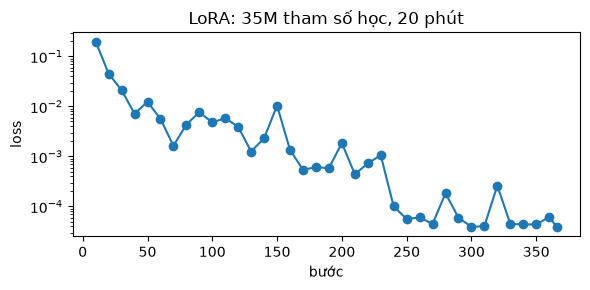

In [9]:
plt.figure(figsize=(6, 3))
plt.plot(history["step"], history["loss"], marker="o")
plt.yscale("log")
plt.xlabel("bước")
plt.ylabel("loss")
plt.title(f"LoRA: {history['trainable_params']/1e6:.0f}M tham số học, {history['seconds']//60} phút")
plt.tight_layout()
plt.show()

## 6. Đổi sang GGUF và nén

UNO Q chạy llama.cpp, nên model phải ở định dạng **GGUF**. Ta tạo bản F16 (giữ nguyên độ chính xác) rồi nén thành nhiều mức:

| Mức | Ý nghĩa |
|---|---|
| F16 | không nén, dùng làm chuẩn so sánh |
| Q8_0, Q5_K_M, Q4_K_M | nén ngày càng mạnh (8, 5, 4 bit mỗi trọng số): file nhỏ hơn, có thể kém chính xác hơn |
| Q4_K_M-imat | như Q4_K_M nhưng có **imatrix**: llama.cpp cho model đọc một đoạn văn bản mẫu (ở đây là chính dữ liệu huấn luyện) để biết trọng số nào quan trọng và nén chúng nhẹ tay hơn |

(AWQ và GPTQ không dùng được vì chỉ chạy trên GPU, còn UNO Q chỉ có CPU ARM.)

In [10]:
calibration_text = gguf_tools.write_calibration_text(TRAIN_FILE, RUN_DIR / "calibration.txt")
gguf_paths = gguf_tools.export_gguf(MERGED_DIR, GGUF_DIR, "Qwen2.5-0.5B-tool", QUANTS, LLAMA_DIR, calibration_text)

pd.DataFrame({"mức nén": list(gguf_paths), "dung lượng (MB)": [round(p.stat().st_size / 2**20, 1) for p in gguf_paths.values()]})

[run] c:\Users\Minor\Downloads\slm\.venv\Scripts\python.exe llama.cpp\convert_hf_to_gguf.py runs\qwen05_A\merged --outfile runs\qwen05_A\gguf\Qwen2.5-0.5B-tool.F16.gguf --outtype f16
[run] llama.cpp\build\bin\Release\llama-quantize.exe runs\qwen05_A\gguf\Qwen2.5-0.5B-tool.F16.gguf runs\qwen05_A\gguf\Qwen2.5-0.5B-tool.Q8_0.gguf Q8_0
[run] llama.cpp\build\bin\Release\llama-quantize.exe runs\qwen05_A\gguf\Qwen2.5-0.5B-tool.F16.gguf runs\qwen05_A\gguf\Qwen2.5-0.5B-tool.Q5_K_M.gguf Q5_K_M
[run] llama.cpp\build\bin\Release\llama-quantize.exe runs\qwen05_A\gguf\Qwen2.5-0.5B-tool.F16.gguf runs\qwen05_A\gguf\Qwen2.5-0.5B-tool.Q4_K_M.gguf Q4_K_M
[run] llama.cpp\build\bin\Release\llama-imatrix.exe -m runs\qwen05_A\gguf\Qwen2.5-0.5B-tool.F16.gguf -f runs\qwen05_A\calibration.txt -o runs\qwen05_A\gguf\Qwen2.5-0.5B-tool.imatrix.dat -ngl 0
[run] llama.cpp\build\bin\Release\llama-quantize.exe --imatrix runs\qwen05_A\gguf\Qwen2.5-0.5B-tool.imatrix.dat runs\qwen05_A\gguf\Qwen2.5-0.5B-tool.F16.gguf runs\

,mức nén,dung lượng (MB)
0,F16,948.1
1,Q8_0,506.5
2,Q5_K_M,400.6
3,Q4_K_M,379.4
4,Q4_K_M-imat,379.4


## 7. Đo từng mức nén

Mỗi mức được đo trên CPU với cả hai bộ câu. Bước này mất lâu nhất (khoảng 30-40 phút cho 5 mức).

In [11]:
items = [(f"fine-tune {quant}", E.ft_cfg(base_cfg, str(path), f"fine-tune {quant}")) for quant, path in gguf_paths.items()]
table = pd.concat([pd.DataFrame([baseline]), E.sweep(items, EVAL_SETS, gpu_layers=0)], ignore_index=True)
table

đang đo: fine-tune F16
đang đo: fine-tune Q8_0
đang đo: fine-tune Q5_K_M
đang đo: fine-tune Q4_K_M
đang đo: fine-tune Q4_K_M-imat


,model,file_mb,ok_156,over_156,p50_156,p95_156,ok_lạ,over_lạ,p50_lạ,p95_lạ,ram_mb
0,Qwen gốc (F16),948.1,0.327,0.917,1.37,1.75,0.314,1.000,1.39,1.80,1075.5
1,fine-tune F16,948.1,1.000,0.000,0.95,1.17,0.968,0.167,0.97,1.17,1046.7
2,fine-tune Q8_0,506.5,1.000,0.000,0.58,0.71,0.968,0.167,0.60,0.72,604.6
3,fine-tune Q5_K_M,400.6,1.000,0.000,0.54,0.72,0.968,0.167,0.56,0.66,505.4
4,fine-tune Q4_K_M,379.4,1.000,0.000,0.55,0.72,0.968,0.167,0.57,0.83,484.3
5,fine-tune Q4_K_M-imat,379.4,1.000,0.000,0.65,1.03,0.968,0.167,0.64,0.78,500.0


### Chọn mức nén

Quy tắc chọn bằng số liệu: lấy **mức có RAM nhỏ nhất** trong số các mức mà điểm trên bộ câu lạ không thấp hơn mức tốt nhất quá `tolerance`
(mặc định 2 điểm phần trăm). Biểu đồ cho thấy sự đánh đổi giữa bộ nhớ và độ chính xác.

Mức được chọn: Q4_K_M (379.4 MB, RAM 484.3 MB, ok_156=1.0, ok_lạ=0.968, p95=0.83 s)


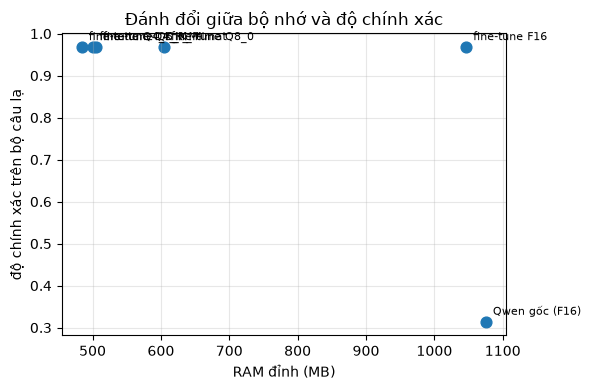

In [12]:
def choose_quant(results, metric="ok_lạ", tolerance=0.02):
    # Chọn mức nén có RAM nhỏ nhất mà điểm không thấp hơn điểm tốt nhất quá `tolerance`.
    tuned = results[results["model"].str.startswith("fine-tune")]
    good_enough = tuned[tuned[metric] >= tuned[metric].max() - tolerance]
    return good_enough.sort_values("ram_mb").iloc[0]


chosen = choose_quant(table)
chosen_quant = chosen["model"].replace("fine-tune ", "")
print(f"Mức được chọn: {chosen_quant} ({chosen['file_mb']} MB, RAM {chosen['ram_mb']} MB, "
      f"ok_156={chosen['ok_156']}, ok_lạ={chosen['ok_lạ']}, p95={chosen['p95_lạ']} s)")

plt.figure(figsize=(6, 4))
plt.scatter(table["ram_mb"], table["ok_lạ"], s=60)
for _, row in table.iterrows():
    plt.annotate(row["model"], (row["ram_mb"], row["ok_lạ"]), textcoords="offset points", xytext=(5, 5), fontsize=8)
plt.xlabel("RAM đỉnh (MB)")
plt.ylabel("độ chính xác trên bộ câu lạ")
plt.title("Đánh đổi giữa bộ nhớ và độ chính xác")
plt.grid(alpha=.3)
plt.tight_layout()
plt.show()

## 8. Model còn sai ở đâu

Chạy lại mức đã chọn trên bộ câu lạ và liệt kê các câu sai: câu nói, công cụ đúng, và công cụ model chọn.
`JSON_HONG` nghĩa là model trả JSON hỏng hoặc bị cắt. Nếu nhiều câu sai cùng một kiểu (ví dụ luôn nhầm hai công cụ cho nhau) thì
đó là chỗ cần thêm dữ liệu.

In [13]:
chosen_cfg = E.ft_cfg(base_cfg, str(gguf_paths[chosen_quant]), f"fine-tune {chosen_quant}")
rows_held = E.evaluate(chosen_cfg, EVAL_SETS["lạ"], f"{chosen_quant} | câu lạ", gpu_layers=0)
E.wrong_cases(rows_held, limit=20)


== Q4_K_M | câu lạ (100s)
{'n': 156, 'ok': 0.968, 'tool_ok': 0.968, 'args_ok|tool_ok': 1.0, 'over_trigger': 0.167, 'tok_tb': 39.5, 'p50_s': 0.63, 'p95_s': 0.76}
nhầm tool (đúng -> model): 4x None->request_line_stop, 1x get_inspection_summary->get_production_stats


,câu,đúng,model,tham số đúng
0,hey i need braek in ten minutes,NaN,request_line_stop,{}
1,give me the quality conrol numbers during toda...,get_inspection_summary,get_production_stats,{'period': 'today'}
2,I need a break in ten minutes.,NaN,request_line_stop,{}
3,um i need a break in ten minutes,NaN,request_line_stop,{}
4,stop muisc,NaN,request_line_stop,{}


## 9. Câu thật (quan trọng nhất, cần nhóm giúp)

Cả bộ 156 câu và bộ giữ riêng đều do chương trình sinh ra từ mẫu câu, nên chỉ cho biết model hiểu **những cách diễn đạt trong khuôn**
của mình. Để biết nó có chịu được lời nói thật hay không, hãy nhờ vài bạn trong nhóm ghi lại khoảng 100 câu họ sẽ nói với hệ thống
(kể cả câu không liên quan đến băng tải), ưu tiên chữ do nhận dạng giọng nói tạo ra.

Chạy ô dưới lần đầu sẽ tạo file `real_utterances.csv` có ví dụ. Thay các dòng ví dụ bằng câu thật rồi chạy lại ô này:
- cột `text`: câu nói;
- cột `tool`: tên công cụ đúng, để trống nếu câu không liên quan đến băng tải;
- cột `args`: tham số dạng JSON, ví dụ `{"target_speed_rpm": 25}`, để trống nếu không có.

In [14]:
REAL_FILE = Path("real_utterances.csv")

if not REAL_FILE.exists():
    E.write_real_template(REAL_FILE)
else:
    real_cases = E.load_real(REAL_FILE)
    rows_real = E.evaluate(chosen_cfg, real_cases, f"{chosen_quant} | câu thật", gpu_layers=0)
    display(E.wrong_cases(rows_real, limit=30))

Mở real_utterances.csv và thay các dòng ví dụ bằng câu thật (mỗi dòng: câu nói, tên tool, tham số JSON).


## 10. Lưu kết quả

Lưu bảng kết quả và cấu hình vào `results/qwen05_A.json` để so sánh với cách B sau này.

In [15]:
Path("results").mkdir(exist_ok=True)
summary = {
    "recipe": "A (cách của Claude)",
    "base": BASE_NAME,
    "lora": LORA,
    "train_examples": history["examples"],
    "train_seconds": history["seconds"],
    "chosen_quant": chosen_quant,
    "table": table.to_dict("records"),
}
json.dump(summary, open("results/qwen05_A.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
print("Đã lưu results/qwen05_A.json")

Đã lưu results/qwen05_A.json


## Cách đọc kết quả

- **So với mốc gốc**: dòng "Qwen gốc" là điểm ban đầu. Mức tăng sau khi dạy là đóng góp của dữ liệu và LoRA.
- **Bộ 156 câu so với bộ câu lạ**: hai điểm gần nhau nghĩa là model hiểu ý, không học thuộc khuôn câu. Điểm 156 câu cao hơn nhiều là dấu hiệu học thuộc.
- **Các mức nén**: nếu Q4 chỉ kém Q8 một hai điểm thì chọn Q4. Nếu kém nhiều thì chọn Q5 hoặc Q8. Nếu Q4 có imatrix tốt hơn Q4 thường thì imatrix có ích.
- **Thời gian**: `p95` dưới 2 giây trên CPU PC là dấu hiệu tốt, nhưng Arduino UNO Q (4 nhân Cortex-A53) chậm hơn PC nhiều, nên cần đo lại trên board thật.
- **Câu thật** (mục 9) mới là phép thử đáng tin nhất cho báo cáo.

**Giới hạn cần nhớ:** dữ liệu dựng theo mẫu câu, chưa có lời nói thật; RAM đo trên PC, chưa phải trên UNO Q.